In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_squared_error, r2_score



### Task 1: Data Loading and Exploration

The historical Bitcoin data was imported from a CSV file into a pandas DataFrame.  
The structure of the dataset was examined by inspecting the column names, number of observations, and data types.

The DataFrame contains $4415$ observations and the following variables:  
$date$, $open$, $close$, $volume$, $high$, $low$, $marketCap$, $timehigh$, and $timelow$.

Most variables are of type $\texttt{float64}$, while date and time-related columns are stored as $\texttt{object}$.

Additionally, the dataset was checked for missing values.

But, the dataset is complete and suitable for further analysis.

In [2]:
#Read the Data
df = pd.read_csv("BTC_daily_historical.csv")

In [3]:
#Basic structure of the df
cols = df.columns.values
num_observations = len(df)
print("The Data Frame has the Columns ", cols)
print("The Data Frame has ", num_observations, " entries")
print("The column´s data types are: \n", df.dtypes)

The Data Frame has the Columns  ['date' 'open' 'close' 'volume' 'high' 'low' 'marketCap' 'timehigh'
 'timelow']
The Data Frame has  4415  entries
The column´s data types are: 
 date          object
open         float64
close        float64
volume       float64
high         float64
low          float64
marketCap    float64
timehigh      object
timelow       object
dtype: object


In [4]:
#Find NaNs
num_nan = df.isna().sum()
print("The total number of NaNs is: \n", num_nan)


The total number of NaNs is: 
 date         0
open         0
close        0
volume       0
high         0
low          0
marketCap    0
timehigh     0
timelow      0
dtype: int64


2013-04-28 00:00:00+00:00
2025-04-24 00:00:00+00:00


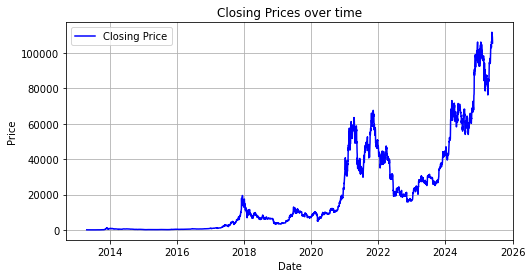

In [5]:
#plot of the closing prices over time
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)
print(df['date'][0])
print(df['date'][4379])

plt.figure(figsize=(8, 4))
plt.plot(df['date'], df['close'], label='Closing Price', color='blue')

plt.title('Closing Prices over time')
plt.xlabel('Date')
plt.ylabel('Price')
plt.grid(True)
plt.legend()

plt.show()

### Task 2: Factor Construction

The following predictors were constructed based on the given formulas:

$MCAP = \log(\text{marketCap})$  
$PRC = \log(p_t)$  
$MAXDPRC = \max(p_{t-6}, \dots, p_t)$  
$Mom_{1,0} = p_t - p_{t-7}$  
$PRCVOL = \log(\text{avg volume over 7 days})$  
$STDPRCVOL = \log(\text{std volume over 7 days})$  
$DAMIHUD = \frac{\text{average absolute return over 7 days}}{PRCVOL}$

In [6]:
EPS = 1e-8 #numerical stability

In [7]:
#MCAP
df['MCAP'] = np.log(df['marketCap'] + EPS)

In [8]:
#PRC
df['PRC']  = np.log(df['close'] + EPS)

In [9]:
#MAXDPRC
df['MAXDPRC'] = df['close'].rolling(window=7, min_periods=7).max()


In [10]:

# 1-week momentum
df['Mom1_0'] = df['close'] - df['close'].shift(7)

# 2-week momentum
df['Mom2_0'] = df['close'] - df['close'].shift(14)

# 3-week momentum
df['Mom3_0'] = df['close'] - df['close'].shift(21)

# 4-week momentum
df['Mom4_0'] = df['close'] - df['close'].shift(28)

# 1-to-4-week momentum (Differenz zwischen Woche 1 und Woche 4)
df['Mom4_1'] = df['close'].shift(7) - df['close'].shift(28)

In [11]:
#PRCVOL
vol_mean_7 = df['volume'].rolling(window=7, min_periods=7).mean()
df['PRCVOL'] = np.log(vol_mean_7 + EPS)


In [12]:
#STDPRCVOL
vol_std_7 = df['volume'].rolling(window=7, min_periods=7).std()
df['STDPRCVOL'] = np.log(vol_std_7 + EPS)


In [13]:
#DAMIHUD
daily_abs_return = df['close'].pct_change().abs()
avg_abs_return_7 = daily_abs_return.rolling(window=7, min_periods=7).mean()

df['DAMIHUD'] = avg_abs_return_7 / (df['PRCVOL'].replace(0, np.nan) + EPS)


### Task 3: Target Variable

The target variable is defined as the $7$-day return based on the closing price:

$R_t = \frac{p_{t+7} - p_t}{p_t}$

Additionally, missing and infinite values were removed to ensure a clean dataset for model training.

In [14]:
df["7_day_return"] = (df["close"].shift(-7) - df["close"]) / df["close"]

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna().copy()

2013-05-26 00:00:00+00:00
2025-05-22 00:00:00+00:00


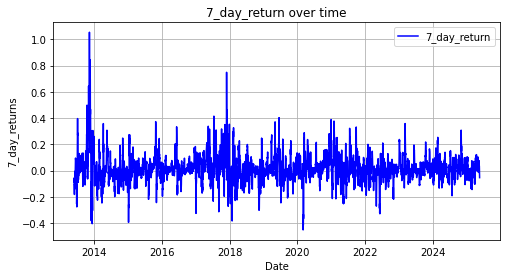

In [15]:
#plot of the closing prices over time
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)
print(df['date'][0])
print(df['date'][4379])

plt.figure(figsize=(8, 4))
plt.plot(df['date'], df['7_day_return'], label='7_day_return', color='blue')

# Styling
plt.title('7_day_return over time')
plt.xlabel('Date')
plt.ylabel('7_day_returns')
plt.grid(True)
plt.legend()

plt.show()

### Task 4: Model Training on Price Data

The features $open$, $close$, $high$, $low$, and $volume$ were used to predict the target variable $7$-day return.

The dataset was split chronologically into training and test sets, where all observations before $2024$ were used for training and the remaining data for out-of-sample testing. This avoids look-ahead bias.

Three models were considered: Linear Regression, Random Forest, and Support Vector Regression (SVR).  
For SVR, feature scaling was applied using standardization.

Hyperparameter tuning was performed using grid search combined with time series cross-validation ($TimeSeriesSplit$ with $5$ splits).  
This validation approach preserves the temporal order of the data and ensures that only past information is used to predict future values, which is crucial for financial time series.

Each model was trained on the training set using the optimal hyperparameters, and performance during cross-validation was evaluated using the mean squared error (MSE).

In [16]:
features = ['open', 'close', 'high', 'low', 'volume'] # only this features areu used in task 4

X = df[features]
y = df['7_day_return']

In [17]:

# split data into two sets according to the task
test = df[df['date'] >= '2024-01-01']

X_train = X[df['date'] < '2024-01-01']
y_train = y[df['date'] < '2024-01-01']

X_test = X[df['date'] >= '2024-01-01']
y_test = y[df['date'] >= '2024-01-01']

In [18]:
tscv = TimeSeriesSplit(n_splits=5) # time-series validation --> no data leakage

In [19]:
models = {
    "LinearRegression": (
        LinearRegression(),
        {}
    ),
    
    "RandomForest": (
        RandomForestRegressor(random_state=42), # grid definition --> hyperparamter tuning
        {
            "n_estimators": [100, 200],
            "max_depth": [5, 10, None],
            "min_samples_split": [2, 5]
        }
    ),
    
    "SVR": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVR())
        ]),
        {
            "model__C": [0.1, 1, 10],
            "model__epsilon": [0.01, 0.1],
            "model__kernel": ["rbf", "linear"]
        }
    )
}

In [20]:
best_models = {}

for name, (model, param_grid) in models.items():
    
    # grid search: best hyperparameter
    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=tscv,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    )
    
    grid.fit(X_train, y_train)
    
    best_models[name] = grid
    
    print(f"\n{name}")
    print("Best Params:", grid.best_params_)
    print("Best CV MSE:", -grid.best_score_)


LinearRegression
Best Params: {}
Best CV MSE: 0.149334312381005

RandomForest
Best Params: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 200}
Best CV MSE: 0.01866397331604704

SVR
Best Params: {'model__C': 0.1, 'model__epsilon': 0.1, 'model__kernel': 'rbf'}
Best CV MSE: 0.01234146606830925


In [21]:
results = {}

for name, grid in best_models.items():
    
    model = grid.best_estimator_
    
    y_pred = model.predict(X_test)
    
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    
    # MAPE 
    mape = np.mean(np.abs((y_test - y_pred) / (y_test + 1e-8))) * 100
    
    r2 = r2_score(y_test, y_pred)
    
    # Win-Loss-Ratio (
    correct_sign = np.sum(np.sign(y_test) == np.sign(y_pred))
    win_loss = correct_sign / len(y_test)
    
    results[name] = {
        "MSE": mse,
        "MAE": mae,
        "MAPE (%)": mape,
        "R2": r2,
        "Win-Loss": win_loss
    }
    
    print(f"\n{name}")
    print("Test MSE:", mse)
    print("Test MAE:", mae)
    print("Test MAPE:", mape)
    print("Test R2:", r2)
    print("Win-Loss Ratio:", win_loss)

results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="MSE")

print("\nModel Comparison:")
print(results_df)


LinearRegression
Test MSE: 0.005984599265368974
Test MAE: 0.05944176265979017
Test MAPE: 899.3988139587165
Test R2: -0.24884224400784216
Win-Loss Ratio: 0.452755905511811

RandomForest
Test MSE: 0.008309890278510756
Test MAE: 0.07261167477383408
Test MAPE: 1975.6827713560683
Test R2: -0.7340746744610136
Win-Loss Ratio: 0.45866141732283466

SVR
Test MSE: 0.0065147686485254284
Test MAE: 0.06042322618704797
Test MAPE: 1363.106201187303
Test R2: -0.35947587089021615
Win-Loss Ratio: 0.4566929133858268

Model Comparison:
                       MSE       MAE     MAPE (%)        R2  Win-Loss
LinearRegression  0.005985  0.059442   899.398814 -0.248842  0.452756
SVR               0.006515  0.060423  1363.106201 -0.359476  0.456693
RandomForest      0.008310  0.072612  1975.682771 -0.734075  0.458661


In [22]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="MSE")

print("\nModel Comparison:")
print(results_df)


Model Comparison:
                       MSE       MAE     MAPE (%)        R2  Win-Loss
LinearRegression  0.005985  0.059442   899.398814 -0.248842  0.452756
SVR               0.006515  0.060423  1363.106201 -0.359476  0.456693
RandomForest      0.008310  0.072612  1975.682771 -0.734075  0.458661


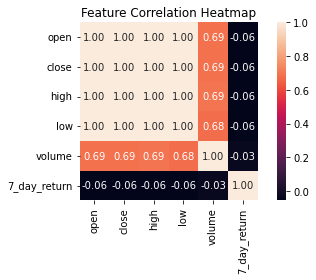

In [23]:
plt.figure()

corr = df[features + ['7_day_return']].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    square=True,
    cbar=True
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

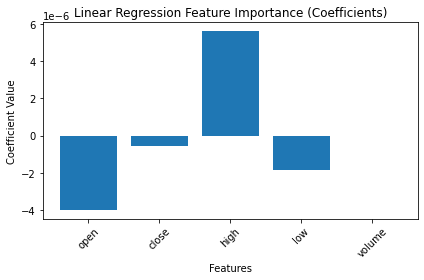

In [24]:
model = best_models["LinearRegression"].best_estimator_

coefs = model.coef_

# Falls 2D → flatten
if coefs.ndim > 1:
    coefs = coefs.flatten()

# Sicherheitscheck
assert len(coefs) == len(features), "Mismatch zwischen Features und Koeffizienten!"

# Plot
plt.figure()
plt.bar(features, coefs)
plt.xticks(rotation=45)
plt.title("Linear Regression Feature Importance (Coefficients)")
plt.xlabel("Features")
plt.ylabel("Coefficient Value")
plt.tight_layout()
plt.show()

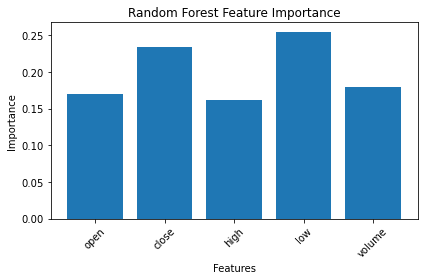

In [25]:
model = best_models["RandomForest"].best_estimator_

importances = model.feature_importances_

# Sicherheitscheck
assert len(importances) == len(features), "Mismatch zwischen Features und Importances!"

# Plot
plt.figure()
plt.bar(features, importances)
plt.xticks(rotation=45)
plt.title("Random Forest Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

### Task 5: Model Training on Financial Factors

The previously constructed financial factors (e.g., $MCAP$, $PRC$, $MAXDPRC$, $Mom_{1,0}$, $PRCVOL$, $STDPRCVOL$, $DAMIHUD$) were used as input features to predict the $7$-day return.

The dataset was again split chronologically into training and test sets, with data before $2024$ used for training and later observations for out-of-sample testing, ensuring no look-ahead bias.

The same models were applied: Linear Regression, Random Forest, and Support Vector Regression (SVR), including feature scaling for SVR.

Hyperparameter tuning was performed using grid search with time series cross-validation ($TimeSeriesSplit$ with $5$ splits).  
This approach maintains the temporal structure of the data and ensures that predictions are always based on past information.

Each model was trained on the training set using the optimal hyperparameters, and performance was evaluated using the mean squared error (MSE).

In [26]:
factor_features = [
    'MCAP',
    'PRC',
    'MAXDPRC',
    'Mom1_0',
    'Mom2_0',
    'Mom3_0',
    'Mom4_0',
    'Mom4_1',
    'PRCVOL',
    'STDPRCVOL',
    'DAMIHUD'
]

X = df[factor_features]
y = df['7_day_return']

In [27]:


# Split nach Datum (statt iloc)
test = df[df['date'] >= '2024-01-01']

X_train = X[df['date'] < '2024-01-01']
y_train = y[df['date'] < '2024-01-01']

X_test = X[df['date'] >= '2024-01-01']
y_test = y[df['date'] >= '2024-01-01']

In [28]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

In [29]:


models_v2 = {
    "LinearRegression": (
        LinearRegression(),
        {}
    ),
    
    "RandomForest": (
        RandomForestRegressor(random_state=42),
        {
            "n_estimators": [500, 1000],
            "max_depth": [ 3,5,10, None],
            "min_samples_split": [15, 20, 25]
        }
    ),
    
    "SVR": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVR())
        ]),
        {
            "model__C": [0.01, 0.1, 1, 10],
            "model__epsilon": [0.01, 0.1, 1],
            "model__kernel": ["rbf", "linear"]
        }
    )
}

In [30]:
from sklearn.model_selection import GridSearchCV

best_models_v2 = {}

for name, (model, param_grid) in models_v2.items():
    
    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=tscv,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    )
    
    grid.fit(X_train, y_train)
    
    best_models_v2[name] = grid
    
    print(f"\n{name}")
    print("Best Params:", grid.best_params_)
    print("Best CV MSE:", -grid.best_score_)


LinearRegression
Best Params: {}
Best CV MSE: 3.1783097531974205

RandomForest
Best Params: {'max_depth': 3, 'min_samples_split': 25, 'n_estimators': 500}
Best CV MSE: 0.0116498625113302

SVR
Best Params: {'model__C': 0.01, 'model__epsilon': 0.1, 'model__kernel': 'rbf'}
Best CV MSE: 0.010247741684747394


In [31]:
results_v2 = {}

for name, grid in best_models_v2.items():
    
    model = grid.best_estimator_
    
    y_pred = model.predict(X_test)
    
    # --- metrics ---
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    
    # MAPE 
    mape = np.mean(np.abs((y_test - y_pred) / (y_test + 1e-8))) * 100
    
    r2 = r2_score(y_test, y_pred)
    
    # Win-Loss Ratio 
    correct_sign = np.sum(np.sign(y_test) == np.sign(y_pred))
    win_loss = correct_sign / len(y_test)
    
    # --- store ---
    results_v2[name] = {
        "MSE": mse,
        "MAE": mae,
        "MAPE (%)": mape,
        "R2": r2,
        "Win-Loss": win_loss
    }
    
    print(f"\n{name}")
    print("Test MSE:", mse)
    print("Test MAE:", mae)
    print("Test MAPE:", mape)
    print("Test R2:", r2)
    print("Win-Loss Ratio:", win_loss)

# --- DataFrame ---
results_df_v2 = pd.DataFrame(results_v2).T
results_df_v2 = results_df_v2.sort_values(by="MSE")

print("\nFactor Model Comparison:")
print(results_df_v2)


LinearRegression
Test MSE: 0.005654842900705961
Test MAE: 0.05860353896440386
Test MAPE: 765.5294306489376
Test R2: -0.18003000443072237
Win-Loss Ratio: 0.5078740157480315

RandomForest
Test MSE: 0.0048608816714298345
Test MAE: 0.05331344048675893
Test MAPE: 409.02493991850054
Test R2: -0.014349349927735844
Win-Loss Ratio: 0.5452755905511811

SVR
Test MSE: 0.004931962292109677
Test MAE: 0.053163544397794096
Test MAPE: 594.5472846854796
Test R2: -0.029182169620269205
Win-Loss Ratio: 0.5748031496062992

Factor Model Comparison:
                       MSE       MAE    MAPE (%)        R2  Win-Loss
RandomForest      0.004861  0.053313  409.024940 -0.014349  0.545276
SVR               0.004932  0.053164  594.547285 -0.029182  0.574803
LinearRegression  0.005655  0.058604  765.529431 -0.180030  0.507874


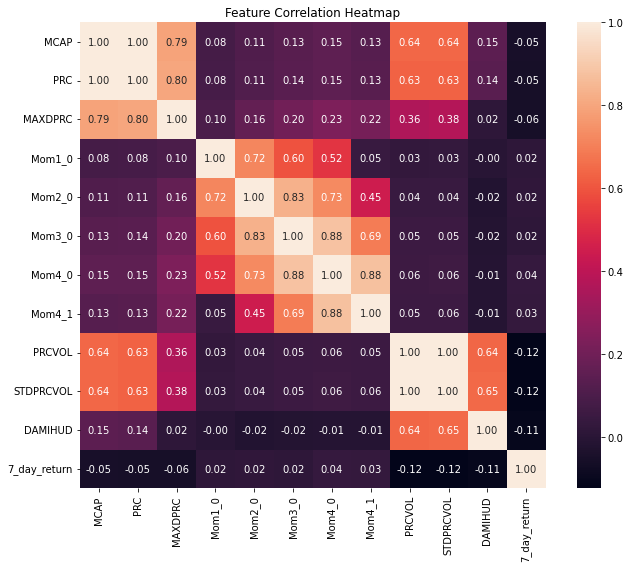

In [32]:
plt.figure(figsize=(10, 8))  

corr = df[factor_features + ['7_day_return']].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    square=True,
    cbar=True
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

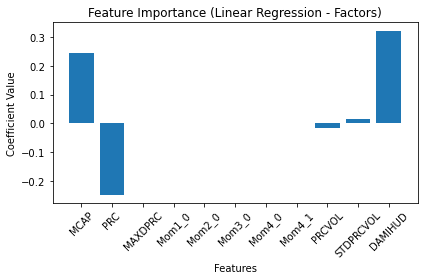

In [33]:
model = best_models_v2["LinearRegression"].best_estimator_

coefs = model.coef_

# if necessary, flatten
if coefs.ndim > 1:
    coefs = coefs.flatten()

feature_names = X_train.columns  # = factor features

# Plot
plt.figure()
plt.bar(feature_names, coefs)
plt.xticks(rotation=45)
plt.title("Feature Importance (Linear Regression - Factors)")
plt.xlabel("Features")
plt.ylabel("Coefficient Value")
plt.tight_layout()
plt.show()

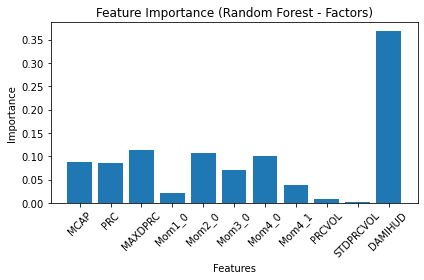

In [34]:
model = best_models_v2["RandomForest"].best_estimator_

importances = model.feature_importances_

feature_names = X_train.columns

plt.figure()
plt.bar(feature_names, importances)
plt.xticks(rotation=45)
plt.title("Feature Importance (Random Forest - Factors)")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

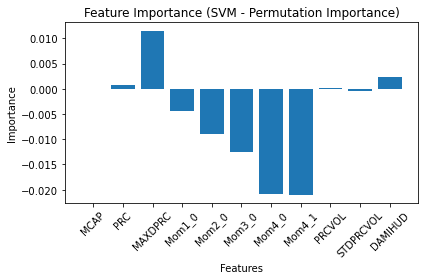

In [35]:
from sklearn.inspection import permutation_importance

model = best_models_v2["SVR"].best_estimator_

result = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importances = result.importances_mean
feature_names = X_test.columns

plt.figure()
plt.bar(feature_names, importances)
plt.xticks(rotation=45)
plt.title("Feature Importance (SVM - Permutation Importance)")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

## Task 6

### Task 6: Model Comparison and Interpretation

#### Price-Based Models (Task 4)

The models trained on raw price and volume data show relatively weak predictive performance.  
All models exhibit negative $R^2$ values, indicating that they are not able to explain the variance of the target variable better than a simple baseline model.  
Error metrics such as MSE and MAE are comparable across models, while the win-loss ratio remains near to $50\%$, suggesting limited directional prediction capability.

The correlation matrix reveals that price-based features (open, close, high, low) are almost perfectly correlated with each other, while their correlation with the $7$-day return is close to zero.  
This indicates a low signal-to-noise ratio and limited predictive information in these variables.

Feature importance plots differ across models, as each model solves a different optimization problem (linear vs. tree-based vs. kernel-based).  
However, due to the strong multicollinearity among price features, coefficient estimates may be unstable and exhibit high variance.

---

#### Factor-Based Models (Task 5)

Using financial factors as input features leads to a significant improvement in model performance.  
The models achieve better error metrics (lower MSE and MAE) and improved win-loss ratios, with all models exceeding $50\%$, indicating better directional accuracy.  
Additionally, $R^2$ values are less negative compared to the price-based models.

The correlation matrix shows that the factors are not strongly correlated with the target variable, but some exhibit moderate correlations among themselves. But to a far lesser extend than in task 4.
This suggests a little bit of multicollinearity, but not that much as before. This is another improvement compared to Task 4.

Feature importance varies across models, reflecting their different learning mechanisms.  

---

#### Conclusion

Overall, models based on financial factors  outperform those based on raw price data, achieving better predictive performance and higher win-loss ratios.  
However, both approaches suffer from a low signal-to-noise ratio, making accurate prediction of Bitcoin returns inherently difficult.

The negative $R^2$ values observed in several models are typical for financial time series, where noise dominates the signal.  
Therefore, metrics such as the win-loss ratio are more informative in this context, as they capture the ability of the model to correctly predict the direction of returns.

In summary, while some predictive power can be extracted, forecasting Bitcoin returns remains challenging due to the complex and highly stochastic nature of the market.

### Task 7: Trading Strategy Evaluation

A trading strategy based on model predictions was implemented using an initial capital of $100{,}000\,€$.

At each time step, the predicted return determines the trading signal:  
a positive prediction ($> 0$) leads to a fully invested position in Bitcoin, while a negative prediction implies holding cash.  
Thus, the strategy follows a binary allocation rule between a risky asset (Bitcoin) and a risk-free position (cash).

The portfolio value evolves over time by applying the realized returns whenever the strategy is invested, resulting in an equity curve for each model.

The performance of all models was compared to a buy-and-hold strategy, where the initial capital is fully invested at the beginning and held until the end of the period.

This comparison shows that, while most models are not able to outperform the passive benchmark, the Support Vector Regression (SVR) model achieves a clear outperformance in this setting.  
This indicates that SVR is able to capture certain short-term patterns in the data and translate them into economically meaningful trading decisions.

However, this result should be interpreted with caution, as the strategy remains highly simplified and the underlying market is characterized by a low signal-to-noise ratio.  
Consequently, the observed outperformance may be sample-specific and not necessarily robust across different time periods.

In [36]:
preds_factors = {}
# store models predictions in a dictionary

for name, grid in best_models_v2.items():
    model = grid.best_estimator_
    preds_factors[name] = model.predict(X_test)

In [37]:
def get_strategy_history(prices, predictions, initial_capital=100_000):
    
    capital = initial_capital
    position = 0  # 0 = cash, 1 = invested
    
    history = []

    for t in range(len(predictions) - 1):
        
        signal = predictions[t]
        
        # --- Signal ---
        if signal > 0:
            position = 1   # invested
        else:
            position = 0   # cash
        
        # --- Return  ---
        if position == 1:
            ret = (prices.iloc[t+1] - prices.iloc[t]) / prices.iloc[t]
            capital *= (1 + ret)
        
        # --- store ---
        history.append(capital)
    
    # append las value
    history.append(capital)
    
    return np.array(history)

In [38]:
def buy_and_hold(prices, initial_capital=100_000):
    return (prices / prices.iloc[0]) * initial_capital

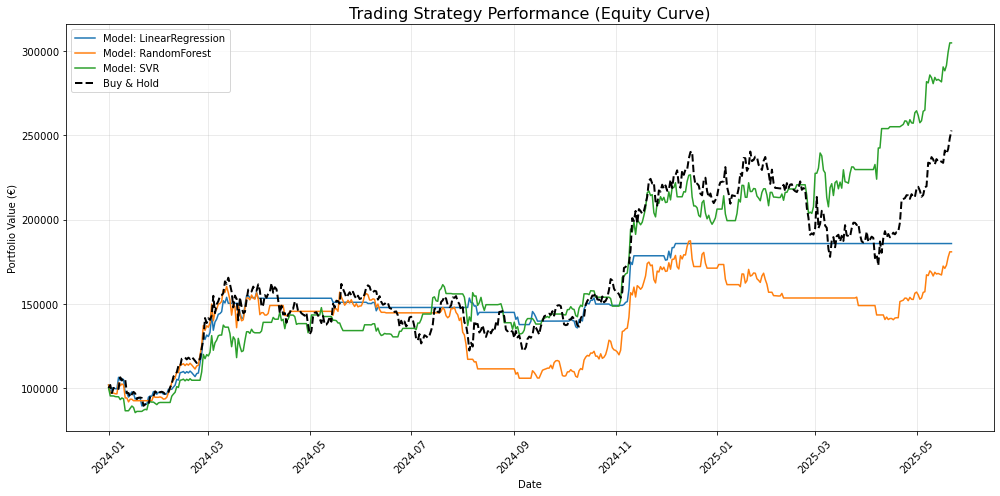

In [39]:
plt.figure(figsize=(14, 7))

prices_test = test['close'].reset_index(drop=True)

# Plot models
for name in preds_factors:
    history = get_strategy_history(prices_test, preds_factors[name])
    plt.plot(test['date'], history, label=f'Model: {name}')

# Buy & Hold
bh_history = buy_and_hold(prices_test)
plt.plot(test['date'], bh_history, label='Buy & Hold', linestyle='--', color='black', linewidth=2)

plt.title('Trading Strategy Performance (Equity Curve)', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Portfolio Value (€)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [40]:
results = []

# Buy & Hold final
bh_final = buy_and_hold(prices_test).iloc[-1]

for name in preds_factors:
    history = get_strategy_history(prices_test, preds_factors[name])
    
    final_value = history[-1]
    
    results.append({
        "Model": name,
        "Final Value (€)": final_value,
        "Return (%)": 100 * (final_value / 100_000 - 1)
    })

# Buy & Hold adding
results.append({
    "Model": "Buy & Hold",
    "Final Value (€)": bh_final,
    "Return (%)": 100 * (bh_final / 100_000 - 1)
})

results_df = pd.DataFrame(results).sort_values("Return (%)", ascending=False)
print(results_df)

              Model  Final Value (€)  Return (%)
2               SVR    304846.180314  204.846180
3        Buy & Hold    252841.372746  152.841373
0  LinearRegression    185742.250271   85.742250
1      RandomForest    180830.848769   80.830849
